# moonshot_ml_sandbox — Phase 2: logistic regression (4 events × 3-rung ladder)

**Question (pre-registered).** Can a model trained only on past years predict the
probability of an event for each stock, beat a naive baseline, and give honest numbers?

**Events** — forward window open(t+1) → open(t+21), ranked *within each date* (market-neutral):

| Event | Fires when | Base rate |
|---|---|---|
| Outperform | forward return above that day's median | 0.50 |
| Top performer | forward return in top 20% | 0.20 |
| Crash | forward return in bottom 20% | 0.20 |
| High vol | forward realized vol in top 20% | 0.20 |

**Ladder** — M0 intercept only (the baseline) · M1 five z-scored features · M2 features + squares.
4 events × 3 rungs, 12 rolling folds (train 3y, test 1y, 21-day purge). Fixed; no tuning after results.

**Scorecard** — skill = 1 − logloss(model)/logloss(M0) · AUC per date, averaged · calibration.
Every headline number gets a month-block bootstrap CI (B=1000).

**Pre-committed reading rules**
1. **M1 beats M0**: skill CI > 0, AUC CI > 0.5, and skill > 0 in both halves (test 2014–19, 2020–25).
2. **M2 beats M1 (real curvature)**: gain CI > 0, gain > **0.002** skill (materiality —
   the self-test showed trivial gains become "significant" at this sample size), and gain > 0 in both halves.
3. **Calibration**: reliability points near the diagonal.
4. **Odds ratios**: same side of 1.0 in most folds.

**Suspicion rule** — return-event AUC > 0.60 (crash > 0.65) → hunt for leakage before interpreting.

**Expectations (stated so they can be wrong)** — outperform AUC ~0.52–0.54; top performer similar or
weaker; crash ~0.55–0.60; high vol ≥ 0.75 with a clear M2 gain.

**Boundary** — predicts the *odds* of events. Says nothing about returns net of costs, or profit.

**Engine** — the code in Cell 2 is byte-for-byte the code that passed the synthetic self-test
(planted strong / U-shape / noise / weak-50% events, calibration, weight recovery, GD = sklearn).

## Cell 0 — Mount and load (read-only)

In [1]:
from google.colab import drive
from pathlib import Path
drive.mount('/content/drive')
SANDBOX_DIR = Path("/content/drive/MyDrive/moonshot_ml_sandbox")
datasets = sorted(SANDBOX_DIR.glob("ml_sandbox_v1_dataset_*.parquet"))
assert datasets, f"No V1 dataset in {SANDBOX_DIR}."
DATASET_PATH = datasets[-1]
PANEL_DIR = Path("/content/drive/MyDrive/moonshot_compounding/features")
panels = sorted(PANEL_DIR.glob("feature_panel_with_pit_v2_*.parquet"))
assert panels, "source panel not found"
print("V1 dataset :", DATASET_PATH.name, "\nsource panel:", panels[-1].name)

Mounted at /content/drive
V1 dataset : ml_sandbox_v1_dataset_2026-09-07.parquet 
source panel: feature_panel_with_pit_v2_2026-07-24.parquet


## Cell 1 — Engine (identical to the self-tested code)

In [2]:
# ==============================================================================
# LOGISTIC-REGRESSION ENGINE  (identical code is self-tested on synthetic data)
# ==============================================================================
import warnings
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

EPS = 1e-12
RUNGS = ["M0", "M1", "M2"]          # M0 intercept only | M1 linear | M2 linear + squares


def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))


def make_folds(dates, train_years=3, purge=21, max_test_year=None):
    # Rolling folds: train on `train_years` calendar years, test on the next one.
    # PURGE: drop the last `purge` trading dates before the train cutoff, so no
    # training card's 21-day forward window reaches into the test year.
    all_dates = np.array(sorted(pd.unique(dates)))
    first_year = pd.Timestamp(all_dates[0]).year
    last_date = pd.Timestamp(all_dates[-1])
    folds = []
    y0 = first_year
    while True:
        tr_lo = pd.Timestamp(f"{y0}-01-01")
        tr_hi = pd.Timestamp(f"{y0 + train_years - 1}-12-31")
        te_lo = pd.Timestamp(f"{y0 + train_years}-01-01")
        te_hi = pd.Timestamp(f"{y0 + train_years}-12-31")
        if te_lo > last_date or (max_test_year is not None and y0 + train_years > max_test_year):
            break
        hi_pos = np.searchsorted(all_dates, np.datetime64(tr_hi), side="right") - 1
        purge_from = pd.Timestamp(all_dates[hi_pos - purge + 1])
        folds.append(dict(test_year=y0 + train_years, train_lo=tr_lo,
                          purge_from=purge_from, train_hi=tr_hi,
                          test_lo=te_lo, test_hi=te_hi))
        y0 += 1
    return folds


def split_fold(frame, f):
    tr = frame[(frame["date"] >= f["train_lo"]) & (frame["date"] < f["purge_from"])]
    te = frame[(frame["date"] >= f["test_lo"]) & (frame["date"] <= f["test_hi"])]
    return tr, te


def design(frame, rung, feats):
    # M0: no features. M1: the z-scored features. M2: features + their squares.
    if rung == "M0":
        return np.zeros((len(frame), 0))
    X = frame[feats].to_numpy(dtype=float)
    if rung == "M2":
        X = np.column_stack([X, X ** 2])
    return X


def fit_logit(X, y):
    # Unregularized maximum-likelihood logistic regression.
    # Returns intercept b, weights w, and whether the optimizer converged.
    y = np.asarray(y, dtype=float)
    if X.shape[1] == 0:
        p = y.mean()
        return dict(b=float(np.log(p / (1 - p))), w=np.zeros(0), converged=True)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        try:
            m = LogisticRegression(penalty=None, solver="lbfgs", max_iter=5000)
            m.fit(X, y)
        except (ValueError, TypeError):   # older sklearn: no penalty=None
            m = LogisticRegression(C=1e10, solver="lbfgs", max_iter=5000)
            m.fit(X, y)
    conv = not any("converge" in str(c.message).lower() for c in caught)
    return dict(b=float(m.intercept_[0]), w=m.coef_[0].copy(), converged=conv)


def predict(model, X):
    return sigmoid(model["b"] + X @ model["w"])


def gradient_descent_logit(X, y, lr=2.0, n_iter=1500):
    # From-scratch fit: w <- w - lr * X^T (p - y) / n  (intercept as a column of 1s)
    Xa = np.column_stack([np.ones(len(X)), X])
    w = np.zeros(Xa.shape[1])
    hist = []
    for _ in range(n_iter):
        p = sigmoid(Xa @ w)
        hist.append(-np.mean(y * np.log(np.clip(p, EPS, 1)) +
                             (1 - y) * np.log(np.clip(1 - p, EPS, 1))))
        w -= lr * Xa.T @ (p - y) / len(y)
    return w, np.array(hist)


def logloss_vec(y, p):
    p = np.clip(p, EPS, 1 - EPS)
    return -(y * np.log(p) + (1 - y) * np.log(1 - p))


def daily_table(dates, y, preds):
    # Per-date sums of log-loss for each rung, and per-date AUC (rank formula).
    # AUC for one date = P(a random event stock outranks a random non-event stock).
    d = pd.DataFrame({"date": dates, "y": y})
    out = {}
    g = d.groupby("date")["y"]
    n = g.size()
    n1 = g.sum()
    n0 = n - n1
    out["n"] = n
    for r, p in preds.items():
        d["ll"] = logloss_vec(d["y"].to_numpy(), p)
        out[f"ll_{r}"] = d.groupby("date")["ll"].sum()
        d["rk"] = pd.Series(p, index=d.index).groupby(d["date"]).rank(method="average")
        sr = d.loc[d["y"] == 1].groupby("date")["rk"].sum().reindex(n.index).fillna(0.0)
        auc = (sr - n1 * (n1 + 1) / 2) / (n1 * n0)
        auc[(n1 == 0) | (n0 == 0)] = np.nan
        out[f"auc_{r}"] = auc
    return pd.DataFrame(out)


def summarize(daily, rung):
    skill = 1 - daily[f"ll_{rung}"].sum() / daily["ll_M0"].sum()
    return skill, daily[f"auc_{rung}"].mean()


def block_bootstrap(daily, B=1000, seed=0):
    # Resample whole calendar MONTHS with replacement (preserves within-month
    # dependence). Returns bootstrap draws of skill/AUC for M1, M2 and the
    # paired M2-minus-M1 skill gain.
    rng = np.random.default_rng(seed)
    month = daily.index.to_period("M")
    agg = pd.DataFrame({
        "ll0": daily["ll_M0"], "ll1": daily["ll_M1"], "ll2": daily["ll_M2"],
        "a1": daily["auc_M1"].fillna(0), "a2": daily["auc_M2"].fillna(0),
        "na": daily["auc_M1"].notna().astype(float),
    }).groupby(month).sum()
    A = agg.to_numpy()
    M = len(agg)
    idx = rng.integers(0, M, size=(B, M))
    C = np.zeros((B, M))
    for b in range(B):
        C[b] = np.bincount(idx[b], minlength=M)
    T = C @ A
    ll0, ll1, ll2, a1, a2, na = T.T
    s1, s2 = 1 - ll1 / ll0, 1 - ll2 / ll0
    return dict(skill_M1=s1, skill_M2=s2, gain=s2 - s1, auc_M1=a1 / na, auc_M2=a2 / na)


def calibration_bins(y, p, n_bins=10):
    b = pd.qcut(pd.Series(p), n_bins, labels=False, duplicates="drop")
    t = pd.DataFrame({"b": b.to_numpy(), "y": y, "p": p}).groupby("b")
    return t["p"].mean().to_numpy(), t["y"].mean().to_numpy(), t.size().to_numpy()


def run_event(frame, event_col, feats, folds, verbose=True):
    # Fit M0/M1/M2 on each fold's TRAIN, score on its TEST. Returns
    # pooled test predictions, per-date scores, per-fold weights, diagnostics.
    sub = frame[frame[event_col].notna()]
    rows, weights, diag = [], [], []
    for f in folds:
        tr, te = split_fold(sub, f)
        if len(tr) == 0 or len(te) == 0:
            continue
        ytr = tr[event_col].to_numpy(float)
        yte = te[event_col].to_numpy(float)
        pred = {}
        for r in RUNGS:
            m = fit_logit(design(tr, r, feats), ytr)
            pred[r] = predict(m, design(te, r, feats))
            weights.append(dict(test_year=f["test_year"], rung=r, b=m["b"],
                                **{f"w{i}": v for i, v in enumerate(m["w"])}))
            if r == "M0":
                diag.append(dict(test_year=f["test_year"], train_rate=ytr.mean(),
                                 test_rate=yte.mean(), b_M0=m["b"],
                                 logit_train_rate=np.log(ytr.mean() / (1 - ytr.mean()))))
            if not m["converged"]:
                print(f"  WARNING: {event_col} {r} fold {f['test_year']} did not converge")
        rows.append(pd.DataFrame({"date": te["date"].to_numpy(),
                                  "ticker": te["ticker"].to_numpy(),
                                  "test_year": f["test_year"], "y": yte,
                                  "p_M0": pred["M0"], "p_M1": pred["M1"], "p_M2": pred["M2"]}))
        if verbose:
            print(f"  {event_col}: fold {f['test_year']} fitted "
                  f"(train {len(tr):,} / test {len(te):,})")
    preds = pd.concat(rows, ignore_index=True)
    daily = daily_table(preds["date"].to_numpy(), preds["y"].to_numpy(),
                        {r: preds[f"p_{r}"].to_numpy() for r in RUNGS})
    daily["test_year"] = pd.Series(pd.to_datetime(daily.index).year, index=daily.index)
    return dict(preds=preds, daily=daily, weights=pd.DataFrame(weights),
                diag=pd.DataFrame(diag))

## Cell 2 — Build the four events

Features come from the V1 dataset unchanged (z-scored within date; universe already
`in_nifty500_flag == 1`). Forward realized vol is reconstructed from the frozen panel with a
vectorized rolling std — verified identical (max diff 5e-17) to the per-stock loop used in the
Phase 5 and Step 2 notebooks. Documented convention (same as those notebooks): the vol window is
daily returns t+1..t+20 (close-to-close), while the return window is open(t+1)→open(t+21).

In [3]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, time
df = pd.read_parquet(DATASET_PATH)
df["date"] = pd.to_datetime(df["date"])
RAW = ["momentum_12_1","reversal_1m","realized_vol_60","log_turnover","overnight_drift"]
Z = [f + "_z" for f in RAW]
NICE = dict(zip(RAW, ["Momentum","Reversal","Realized vol","Log-turnover","Overnight drift"]))

panel = pd.read_parquet(panels[-1], columns=["Date","ticker","daily_return"])
panel["Date"] = pd.to_datetime(panel["Date"]).dt.tz_localize(None)
panel = panel.sort_values(["ticker","Date"]).reset_index(drop=True)
panel["fwd_vol"] = (panel.groupby("ticker")["daily_return"]
                    .transform(lambda s: s.rolling(20, min_periods=10).std().shift(-20)))
df = df.merge(panel[["Date","ticker","fwd_vol"]], left_on=["date","ticker"],
              right_on=["Date","ticker"], how="left").drop(columns=["Date"])
df = df.sort_values(["date","ticker"]).reset_index(drop=True)

pct = lambda c: df.groupby("date")[c].rank(pct=True)
r = pct("fwd_ret_20d")
df["ev_outperform"] = (r > 0.5).astype(float)
df["ev_top"]        = (r > 0.8).astype(float)
df["ev_crash"]      = (r <= 0.2).astype(float)
hv = pct("fwd_vol")
df["ev_highvol"] = np.where(df["fwd_vol"].notna(), (hv > 0.8).astype(float), np.nan)

EVENTS = {"ev_outperform":"Outperform","ev_top":"Top performer",
          "ev_crash":"Crash","ev_highvol":"High vol"}
BASE = {"ev_outperform":0.5,"ev_top":0.2,"ev_crash":0.2,"ev_highvol":0.2}
print(f"{len(df):,} cards | {df['date'].min().date()} -> {df['date'].max().date()}")
print(f"forward vol non-null: {df['fwd_vol'].notna().mean()*100:.2f}%")
print("\nTRIPWIRE — event rates (must match base rates):")
for e, name in EVENTS.items():
    rate = df[e].mean()
    print(f"  {name:<14} {rate:.4f}  (expected {BASE[e]:.2f})  n={df[e].notna().sum():,}")
    assert abs(rate - BASE[e]) < 0.01, f"{name} rate off — stop and debug"

1,813,407 cards | 2011-01-03 -> 2026-06-10
forward vol non-null: 100.00%

TRIPWIRE — event rates (must match base rates):
  Outperform     0.5006  (expected 0.50)  n=1,813,407
  Top performer  0.2009  (expected 0.20)  n=1,813,407
  Crash          0.1993  (expected 0.20)  n=1,813,407
  High vol       0.2009  (expected 0.20)  n=1,813,364


## Cell 3 — Folds and purge (printed, not assumed)

In [4]:
folds = make_folds(df["date"], max_test_year=2025)   # pre-registered: 12 folds, 2014-2025
print(f"{len(folds)} folds\n{'test':<6}{'train (kept)':<26}{'purged':<26}")
for f in folds:
    tr, te = split_fold(df, f)
    assert tr["date"].max() < f["purge_from"] <= f["train_hi"] < te["date"].min()
    print(f"{f['test_year']:<6}{str(f['train_lo'].date())+'..'+str(tr['date'].max().date()):<26}"
          f"{str(f['purge_from'].date())+'..'+str(f['train_hi'].date()):<26}")
print("\n[PASS] every fold: last train date < purge start <= train cutoff < first test date")

12 folds
test  train (kept)              purged                    
2014  2011-01-01..2013-11-29    2013-12-02..2013-12-31    
2015  2012-01-01..2014-12-01    2014-12-02..2014-12-31    
2016  2013-01-01..2015-12-01    2015-12-02..2015-12-31    
2017  2014-01-01..2016-12-01    2016-12-02..2016-12-31    
2018  2015-01-01..2017-11-29    2017-11-30..2017-12-31    
2019  2016-01-01..2018-11-29    2018-11-30..2018-12-31    
2020  2017-01-01..2019-11-29    2019-12-02..2019-12-31    
2021  2018-01-01..2020-12-01    2020-12-02..2020-12-31    
2022  2019-01-01..2021-12-02    2021-12-03..2021-12-31    
2023  2020-01-01..2022-12-01    2022-12-02..2022-12-31    
2024  2021-01-01..2023-11-29    2023-11-30..2023-12-31    
2025  2022-01-01..2024-11-29    2024-12-02..2024-12-31    

[PASS] every fold: last train date < purge start <= train cutoff < first test date


## Cell 4 — From-scratch gradient descent vs sklearn (one fold)

High-vol event, M1, the fold that tests 2020. The from-scratch loop is
`w ← w − lr·Xᵀ(p − y)/n`; it must land on sklearn's weights.

                        GD   sklearn
intercept          -1.6123   -1.6123
Momentum           -0.1249   -0.1250
Reversal           -0.1502   -0.1502
Realized vol       +1.0766   +1.0766
Log-turnover       -0.0362   -0.0362
Overnight drift    +0.0512   +0.0512
max |GD - sklearn| = 8.5e-05
  [saved: 01_gd_convergence.png]


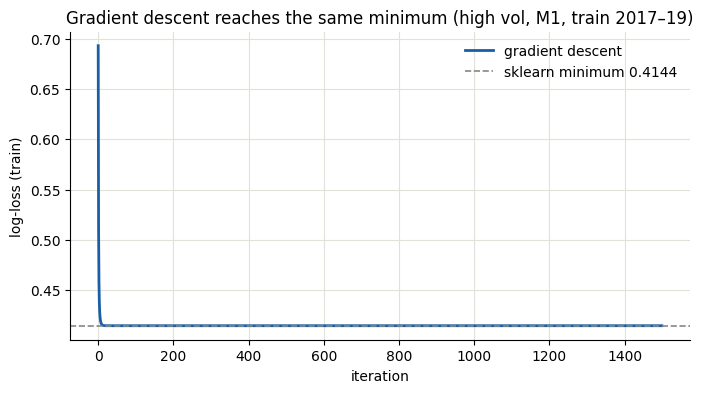

In [5]:
EXPORT_DIR = SANDBOX_DIR / "viz_exports_phase2_logit"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
_n = {"k": 0}
def save_fig(fig, name):
    _n["k"] += 1; p = EXPORT_DIR / f"{_n['k']:02d}_{name}.png"
    fig.savefig(p, dpi=130, bbox_inches="tight"); print(f"  [saved: {p.name}]")

EV_COL = {"ev_outperform":"#2a78d6","ev_top":"#eb6834","ev_crash":"#1baf7a","ev_highvol":"#eda100"}
FEAT_COL = ["#2a78d6","#eb6834","#1baf7a","#eda100","#e87ba4"]
FEAT_MK = ["o","s","^","D","v"]
RUNG_COL = {"M0":"#b4b2a9","M1":"#85b7eb","M2":"#185fa5"}
plt.rcParams.update({"axes.spines.top":False,"axes.spines.right":False,
                     "axes.grid":True,"grid.color":"#e1e0d9","grid.linewidth":0.8})

f20 = next(f for f in folds if f["test_year"] == 2020)
sub = df[df["ev_highvol"].notna()]
tr, _ = split_fold(sub, f20)
X = design(tr, "M1", Z); y = tr["ev_highvol"].to_numpy(float)
m = fit_logit(X, y)
w_gd, hist = gradient_descent_logit(X, y)
exact = np.r_[m["b"], m["w"]]
print(f"{'':<16}{'GD':>10}{'sklearn':>10}")
for name, a, b in zip(["intercept"] + [NICE[r] for r in RAW], w_gd, exact):
    print(f"{name:<16}{a:>+10.4f}{b:>+10.4f}")
print(f"max |GD - sklearn| = {np.abs(w_gd-exact).max():.1e}")
ll_exact = np.mean(logloss_vec(y, predict(m, X)))
fig, ax = plt.subplots(figsize=(8,4))
ax.plot(hist, color="#185fa5", lw=2, label="gradient descent")
ax.axhline(ll_exact, color="#888780", ls="--", lw=1.2, label=f"sklearn minimum {ll_exact:.4f}")
ax.set_xlabel("iteration"); ax.set_ylabel("log-loss (train)")
ax.set_title("Gradient descent reaches the same minimum (high vol, M1, train 2017–19)")
ax.legend(frameon=False); save_fig(fig, "gd_convergence"); plt.show()

## Cell 5 — Fit all folds × events × rungs (the slow cell)

In [6]:
t0 = time.time()
RES = {}
for e, name in EVENTS.items():
    print(f"\n{name}")
    RES[e] = run_event(df, e, Z, folds)
print(f"\ndone in {(time.time()-t0)/60:.1f} min")


Outperform
  ev_outperform: fold 2014 fitted (train 340,294 / test 116,264)
  ev_outperform: fold 2015 fitted (train 340,727 / test 118,763)
  ev_outperform: fold 2016 fitted (train 343,150 / test 120,184)
  ev_outperform: fold 2017 fitted (train 344,884 / test 121,031)
  ev_outperform: fold 2018 fitted (train 349,577 / test 121,535)
  ev_outperform: fold 2019 fitted (train 352,652 / test 119,811)
  ev_outperform: fold 2020 fitted (train 352,034 / test 123,486)
  ev_outperform: fold 2021 fitted (train 354,409 / test 122,467)
  ev_outperform: fold 2022 fitted (train 355,601 / test 120,489)
  ev_outperform: fold 2023 fitted (train 356,402 / test 120,587)
  ev_outperform: fold 2024 fitted (train 353,193 / test 116,061)
  ev_outperform: fold 2025 fitted (train 346,740 / test 90,510)

Top performer
  ev_top: fold 2014 fitted (train 340,294 / test 116,264)
  ev_top: fold 2015 fitted (train 340,727 / test 118,763)
  ev_top: fold 2016 fitted (train 343,150 / test 120,184)
  ev_top: fold 2017 

## Cell 6 — Tripwires on the baseline rung

In [7]:
for e, name in EVENTS.items():
    d = RES[e]["diag"]; dl = RES[e]["daily"]
    b_gap = (d["b_M0"] - d["logit_train_rate"]).abs().max()
    base = BASE[e]; ll_theory = -(base*np.log(base) + (1-base)*np.log(1-base))
    ll0 = dl["ll_M0"].sum() / dl["n"].sum()
    auc0 = dl["auc_M0"].mean()
    print(f"{name:<14} M0 intercept {d['b_M0'].mean():+.3f} (logit of base {np.log(base/(1-base)):+.3f}) | "
          f"test log-loss {ll0:.4f} (theory {ll_theory:.4f}) | M0 AUC {auc0:.3f}")
    assert b_gap < 1e-6 and abs(ll0 - ll_theory) < 0.005 and abs(auc0 - 0.5) < 1e-9
print("\n[PASS] baseline rung behaves exactly as theory says for all events")

Outperform     M0 intercept +0.002 (logit of base +0.000) | test log-loss 0.6931 (theory 0.6931) | M0 AUC 0.500
Top performer  M0 intercept -1.381 (logit of base -1.386) | test log-loss 0.5016 (theory 0.5004) | M0 AUC 0.500
Crash          M0 intercept -1.391 (logit of base -1.386) | test log-loss 0.4994 (theory 0.5004) | M0 AUC 0.500
High vol       M0 intercept -1.381 (logit of base -1.386) | test log-loss 0.5016 (theory 0.5004) | M0 AUC 0.500

[PASS] baseline rung behaves exactly as theory says for all events


## Cell 7 — Scorecard with bootstrap CIs, halves, and the pre-committed verdicts

In [8]:
ci = lambda x: np.percentile(x, [2.5, 97.5])
BOOT, rows = {}, []
for e, name in EVENTS.items():
    dl = RES[e]["daily"]; bt = block_bootstrap(dl, B=1000); BOOT[e] = bt
    early, late = dl[dl["test_year"] <= 2019], dl[dl["test_year"] >= 2020]
    s1, a1 = summarize(dl, "M1"); s2, a2 = summarize(dl, "M2")
    s1e, _ = summarize(early, "M1"); s1l, _ = summarize(late, "M1")
    s2e, _ = summarize(early, "M2"); s2l, _ = summarize(late, "M2")
    g_ci = ci(bt["gain"])
    rule1 = ci(bt["skill_M1"])[0] > 0 and ci(bt["auc_M1"])[0] > 0.5 and s1e > 0 and s1l > 0
    rule2 = g_ci[0] > 0 and (s2 - s1) > 0.002 and (s2e - s1e) > 0 and (s2l - s1l) > 0
    rows.append(dict(event=name,
        M1_skill=s1, M1_skill_lo=ci(bt["skill_M1"])[0], M1_skill_hi=ci(bt["skill_M1"])[1],
        M1_auc=a1, M1_auc_lo=ci(bt["auc_M1"])[0], M1_auc_hi=ci(bt["auc_M1"])[1],
        M2_skill=s2, M2_auc=a2, M2_auc_lo=ci(bt["auc_M2"])[0], M2_auc_hi=ci(bt["auc_M2"])[1],
        gain=s2-s1, gain_lo=g_ci[0], gain_hi=g_ci[1],
        M1_skill_early=s1e, M1_skill_late=s1l, M2_skill_early=s2e, M2_skill_late=s2l,
        rule1_M1_beats_M0=rule1, rule2_M2_material=rule2))
score = pd.DataFrame(rows)
pd.set_option("display.width", 200)
print(score.to_string(index=False, float_format=lambda x: f"{x:+.4f}"))

print("\nSUSPICION CHECK")
for _, r in score.iterrows():
    lim = 0.65 if r["event"] == "Crash" else (None if r["event"] == "High vol" else 0.60)
    best = max(r["M1_auc"], r["M2_auc"])
    if lim is not None:
        flag = "LEAKAGE HUNT BEFORE INTERPRETING" if best > lim else "ok"
        print(f"  {r['event']:<14} best AUC {best:.3f} vs limit {lim:.2f} -> {flag}")

        event  M1_skill  M1_skill_lo  M1_skill_hi  M1_auc  M1_auc_lo  M1_auc_hi  M2_skill  M2_auc  M2_auc_lo  M2_auc_hi    gain  gain_lo  gain_hi  M1_skill_early  M1_skill_late  M2_skill_early  M2_skill_late  rule1_M1_beats_M0  rule2_M2_material
   Outperform   +0.0027      +0.0002      +0.0052 +0.5371    +0.5255    +0.5493   +0.0026 +0.5368    +0.5253    +0.5485 -0.0001  -0.0004  +0.0002         +0.0050        +0.0003         +0.0049        +0.0003               True              False
Top performer   +0.0022      +0.0006      +0.0037 +0.5366    +0.5274    +0.5459   +0.0025 +0.5399    +0.5306    +0.5491 +0.0003  -0.0003  +0.0009         +0.0021        +0.0022         +0.0025        +0.0024               True              False
        Crash   +0.0192      +0.0134      +0.0245 +0.5957    +0.5820    +0.6086   +0.0204 +0.5984    +0.5847    +0.6115 +0.0013  +0.0005  +0.0021         +0.0282        +0.0098         +0.0298        +0.0107               True              False
     High vol   

## Cell 8 — Charts

  [saved: 02_headline_skill_auc.png]


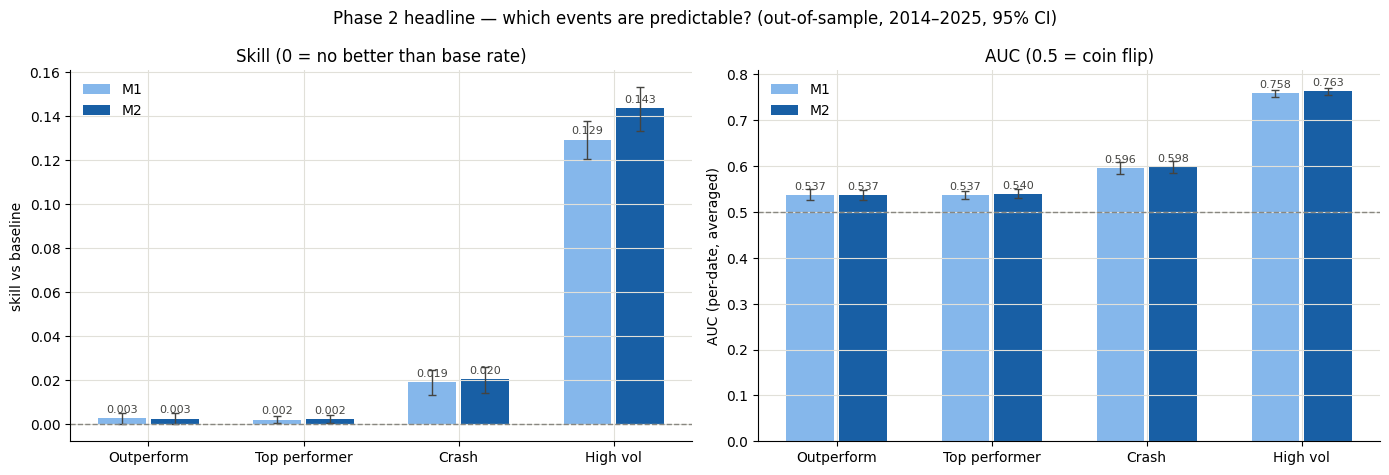

In [9]:
# CHART A — headline: skill and AUC by event, M1 vs M2, with 95% CIs
names = list(EVENTS.values()); xs = np.arange(len(names)); bw = 0.34
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, metric in zip(axes, ["skill", "auc"]):
    for k, rg in enumerate(["M1", "M2"]):
        vals, err = [], [[], []]
        for e in EVENTS:
            bt = BOOT[e][f"{metric}_{rg}"]; dl = RES[e]["daily"]
            v = summarize(dl, rg)[0 if metric == "skill" else 1]
            lo, hi = ci(bt); vals.append(v); err[0].append(v - lo); err[1].append(hi - v)
        bars = ax.bar(xs + (k - 0.5) * bw, vals, bw * 0.9, color=RUNG_COL[rg], label=rg,
               yerr=err, capsize=3, error_kw=dict(ecolor="#444441", lw=1))
        for bx, v in zip(bars, vals):   # direct labels: small return-event values stay readable
            ax.annotate(f"{v:.3f}", (bx.get_x() + bx.get_width() / 2, v), xytext=(0, 4),
                        textcoords="offset points", ha="center", fontsize=8, color="#444441")
    ax.axhline(0 if metric == "skill" else 0.5, color="#888780", lw=1, ls="--")
    ax.set_xticks(xs); ax.set_xticklabels(names)
    ax.set_ylabel("skill vs baseline" if metric == "skill" else "AUC (per-date, averaged)")
    ax.set_title("Skill (0 = no better than base rate)" if metric == "skill"
                 else "AUC (0.5 = coin flip)")
    ax.legend(frameon=False)
fig.suptitle("Phase 2 headline — which events are predictable? (out-of-sample, 2014–2025, 95% CI)")
fig.tight_layout(); save_fig(fig, "headline_skill_auc"); plt.show()

  [saved: 03_skill_by_fold.png]


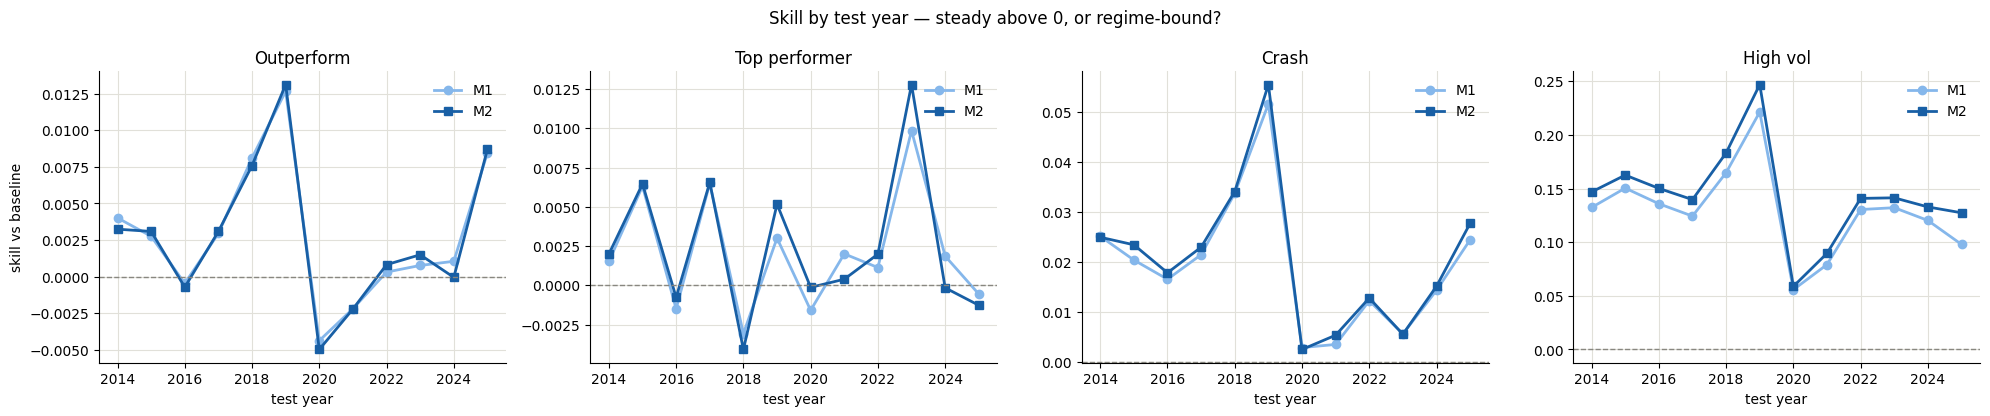

In [10]:
# CHART B — skill per fold (is it steady or regime-bound?)
fig, axes = plt.subplots(1, 4, figsize=(20, 4.2), sharex=True)
for ax, (e, name) in zip(axes, EVENTS.items()):
    dl = RES[e]["daily"]; yrs = sorted(dl["test_year"].unique())
    for rg, mk in [("M1", "o"), ("M2", "s")]:
        ax.plot(yrs, [summarize(dl[dl["test_year"] == y], rg)[0] for y in yrs],
                marker=mk, ms=6, lw=2, color=RUNG_COL[rg], label=rg)
    ax.axhline(0, color="#888780", lw=1, ls="--")
    ax.set_title(name); ax.set_xlabel("test year"); ax.legend(frameon=False)
axes[0].set_ylabel("skill vs baseline")
fig.suptitle("Skill by test year — steady above 0, or regime-bound?")
fig.tight_layout(); save_fig(fig, "skill_by_fold"); plt.show()

  [saved: 04_reliability.png]


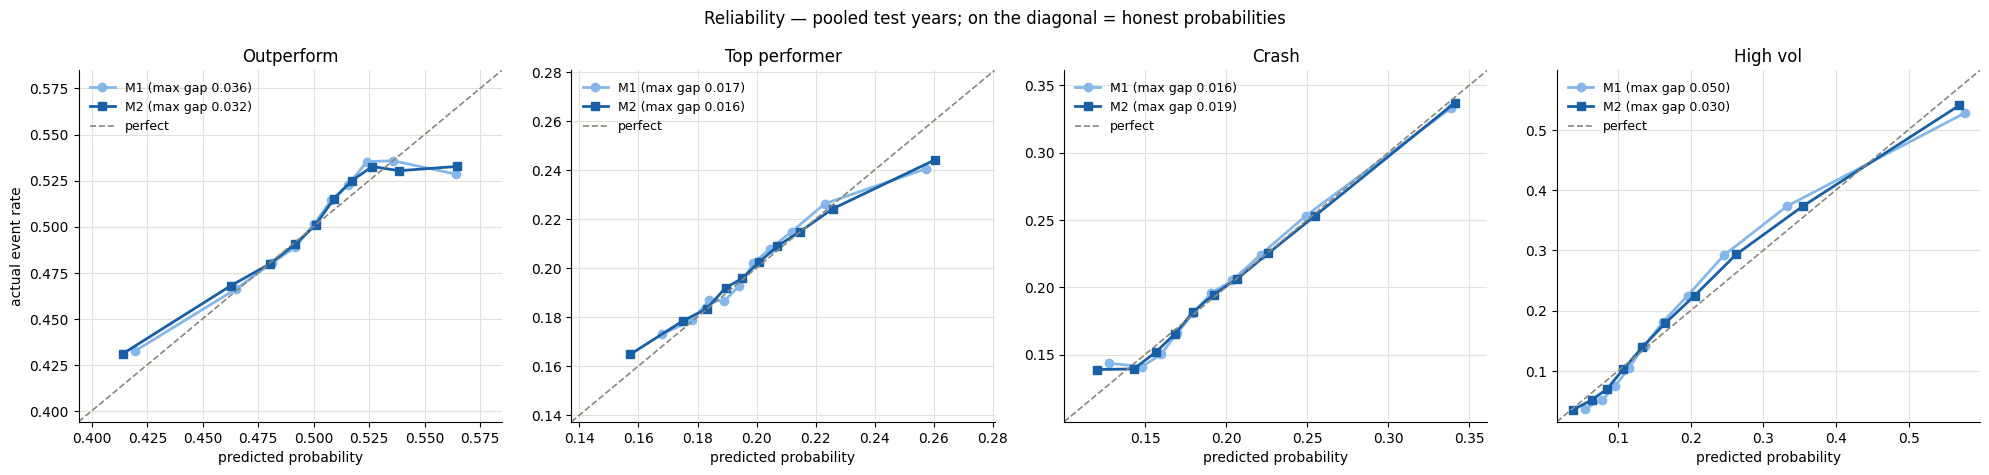

In [11]:
# CHART C — reliability diagrams (do the numbers mean what they say?)
fig, axes = plt.subplots(1, 4, figsize=(20, 4.8))
CAL = {}
for ax, (e, name) in zip(axes, EVENTS.items()):
    pr = RES[e]["preds"]; lo_all, hi_all = 1, 0
    for rg, mk in [("M1", "o"), ("M2", "s")]:
        mp, ma, _ = calibration_bins(pr["y"].to_numpy(), pr[f"p_{rg}"].to_numpy())
        CAL[(e, rg)] = np.abs(mp - ma).max()
        ax.plot(mp, ma, marker=mk, ms=6, lw=2, color=RUNG_COL[rg],
                label=f"{rg} (max gap {CAL[(e, rg)]:.3f})")
        lo_all, hi_all = min(lo_all, mp.min(), ma.min()), max(hi_all, mp.max(), ma.max())
    pad = 0.02; lim = [max(0, lo_all - pad), min(1, hi_all + pad)]
    ax.plot(lim, lim, color="#888780", ls="--", lw=1.2, label="perfect")
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_title(name); ax.set_xlabel("predicted probability"); ax.legend(frameon=False, fontsize=9)
axes[0].set_ylabel("actual event rate")
fig.suptitle("Reliability — pooled test years; on the diagonal = honest probabilities")
fig.tight_layout(); save_fig(fig, "reliability"); plt.show()

  [saved: 05_odds_ratios.png]


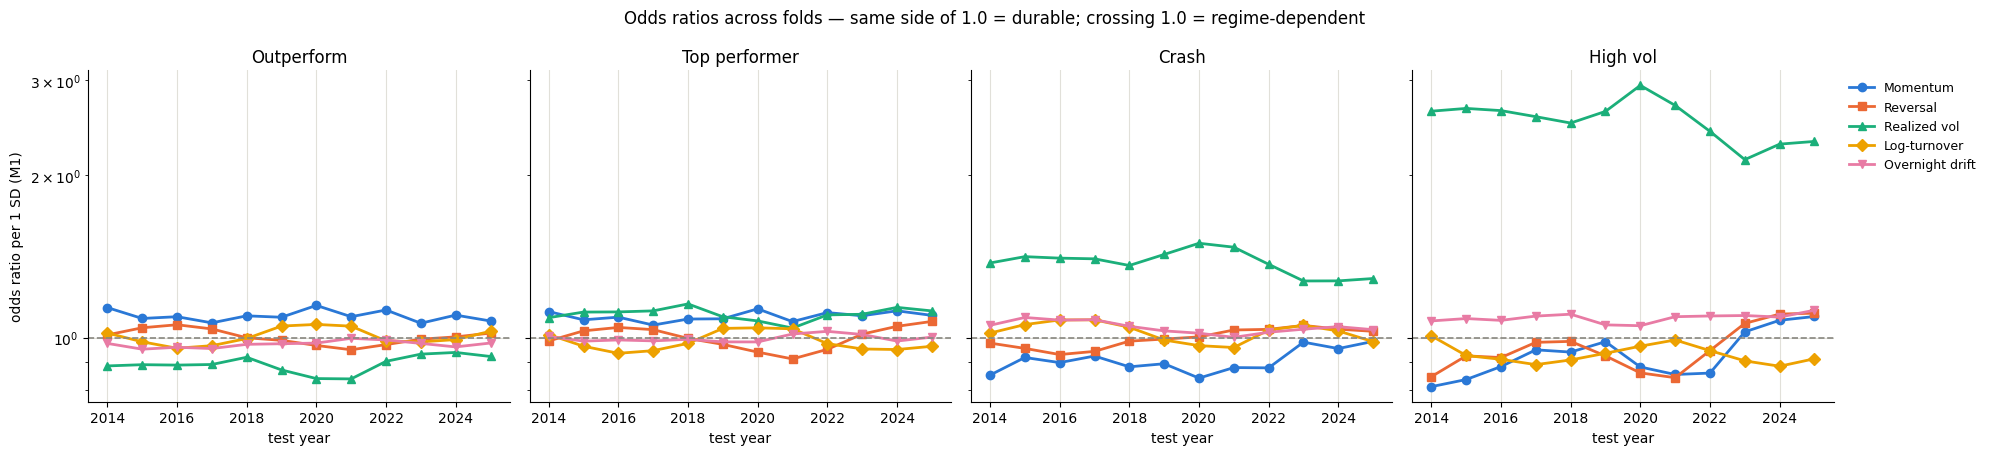

In [12]:
# CHART D — M1 odds ratios per feature across folds (log scale; 1 = no effect)
fig, axes = plt.subplots(1, 4, figsize=(20, 4.6), sharey=True)
for ax, (e, name) in zip(axes, EVENTS.items()):
    W = RES[e]["weights"]; W = W[W["rung"] == "M1"]
    for i, f in enumerate(RAW):
        ax.plot(W["test_year"], np.exp(W[f"w{i}"]), marker=FEAT_MK[i], ms=6, lw=2,
                color=FEAT_COL[i], label=NICE[f])
    ax.axhline(1, color="#888780", ls="--", lw=1.2); ax.set_yscale("log")
    ax.set_title(name); ax.set_xlabel("test year")
axes[0].set_ylabel("odds ratio per 1 SD (M1)")
axes[-1].legend(frameon=False, fontsize=9, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.suptitle("Odds ratios across folds — same side of 1.0 = durable; crossing 1.0 = regime-dependent")
fig.tight_layout(); save_fig(fig, "odds_ratios"); plt.show()

  [saved: 06_model_vs_table.png]


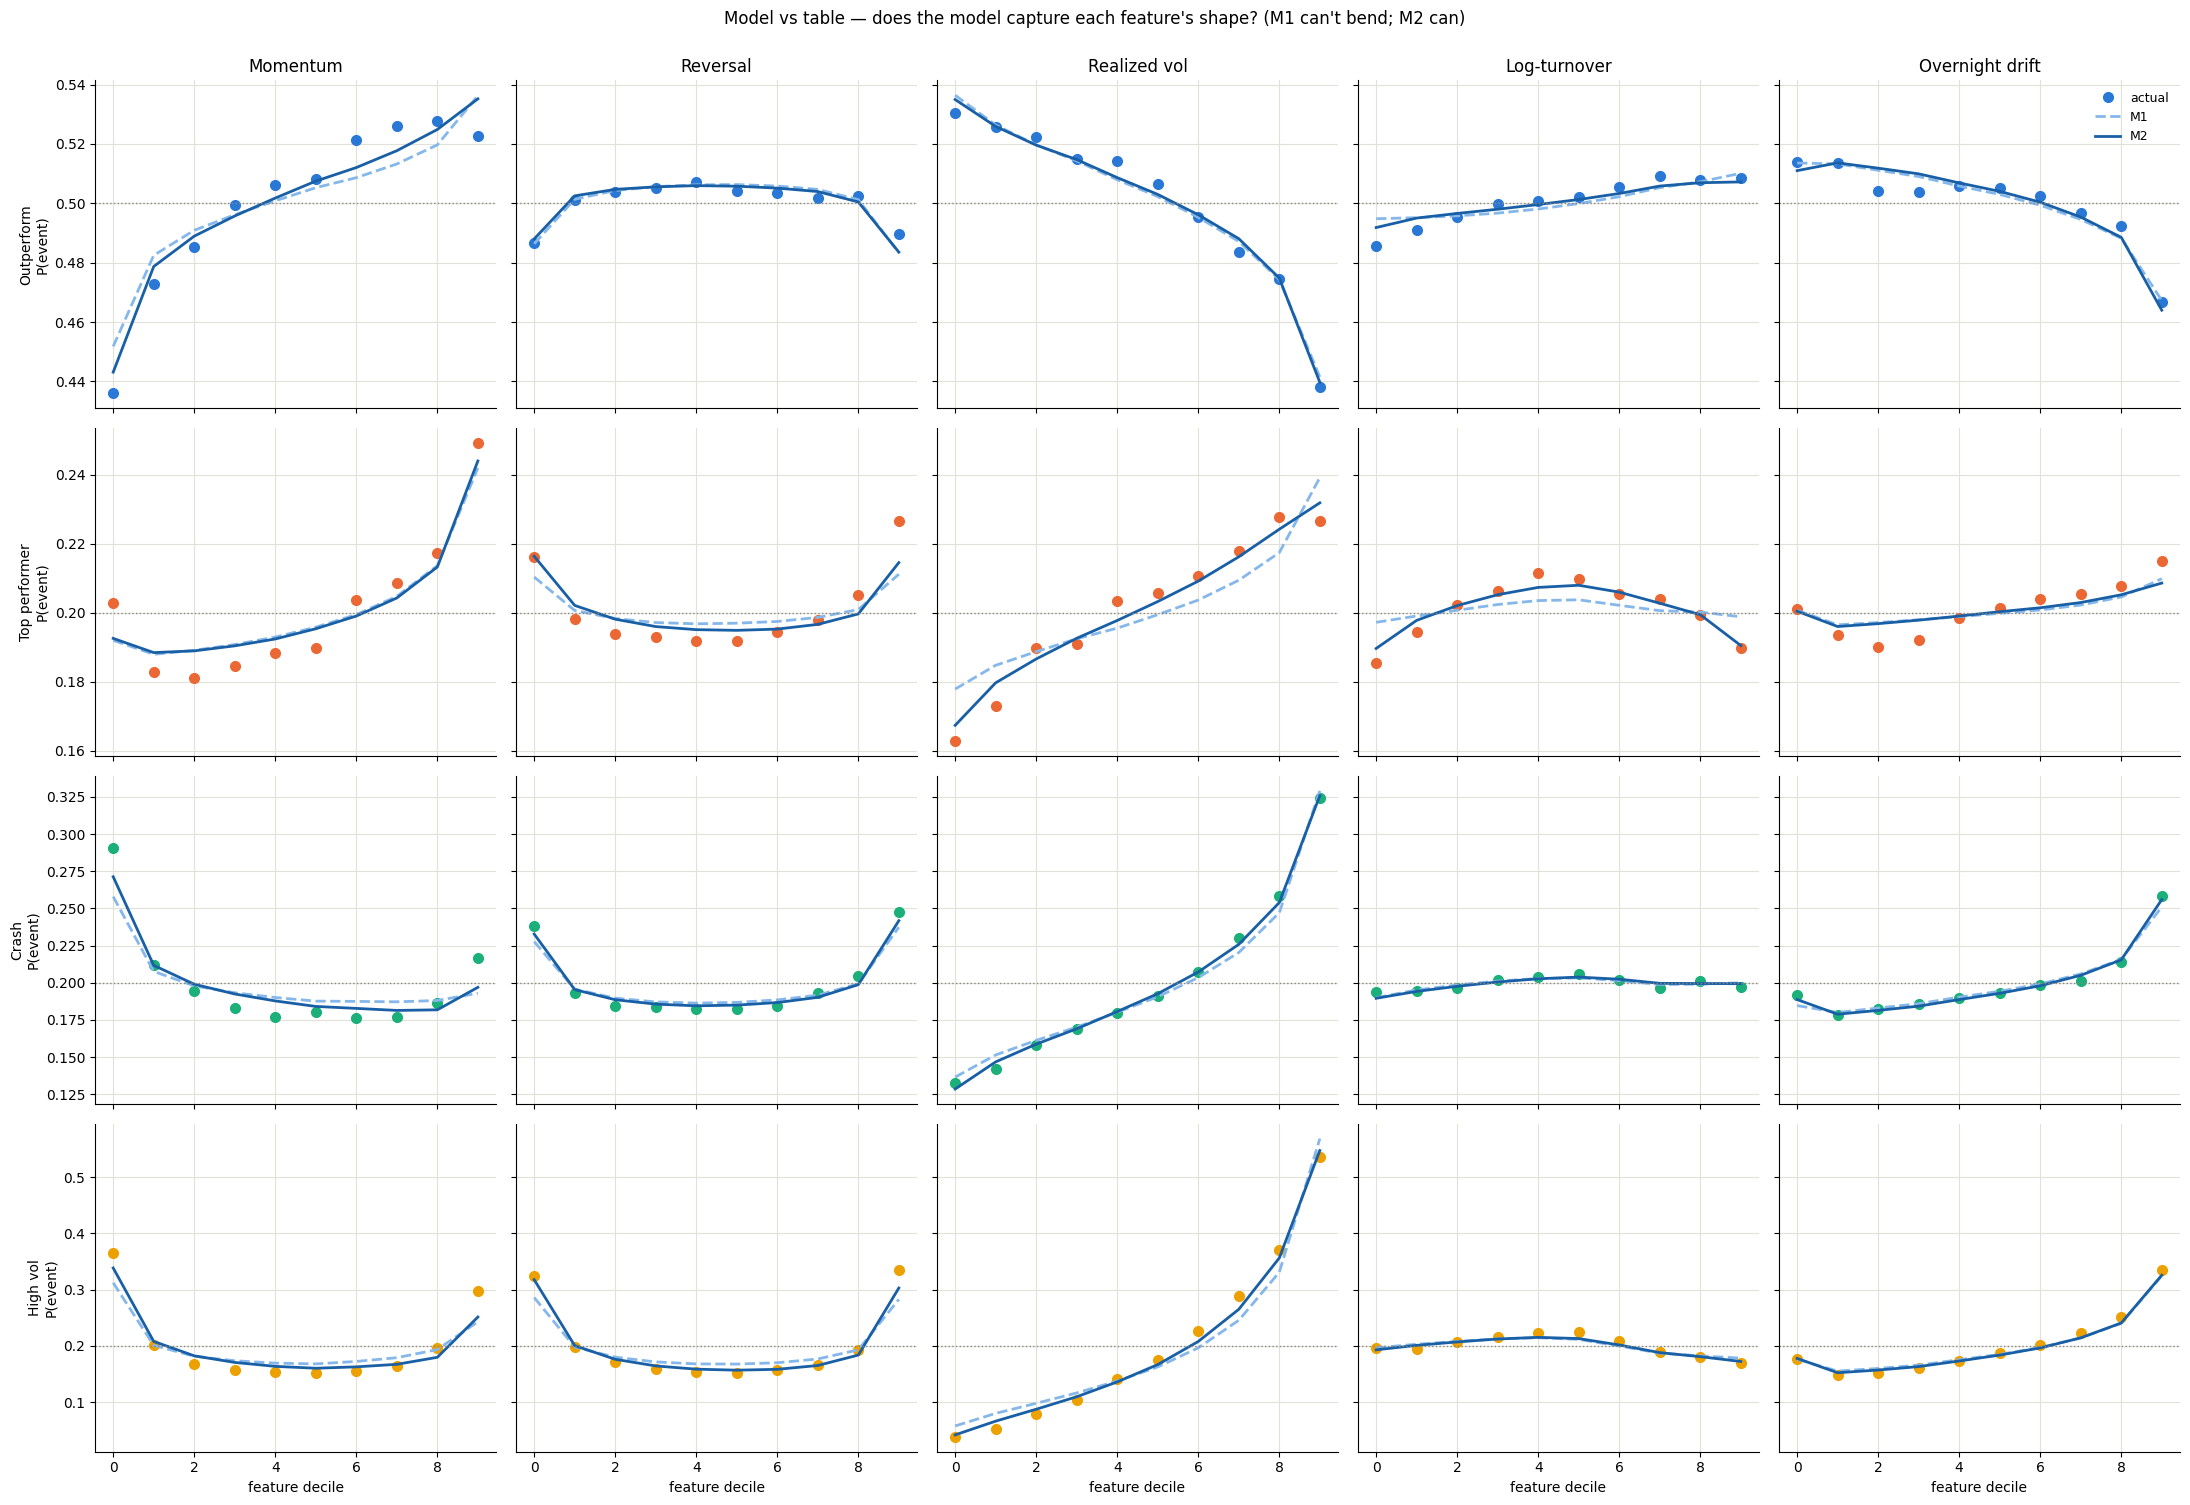

In [13]:
# CHART E — model vs table: actual decile rates (dots) vs M1/M2 average prediction.
# Deciles here are pooled over the test years (a diagnostic view, not a trading rule).
fig, axes = plt.subplots(4, 5, figsize=(22, 15), sharex=True, sharey="row")  # shared y per event: noise looks flat
MVT = {}
for row, (e, name) in enumerate(EVENTS.items()):
    pr = RES[e]["preds"].merge(df[["date", "ticker"] + Z], on=["date", "ticker"], how="left")
    for col, f in enumerate(RAW):
        ax = axes[row, col]
        dec = pd.qcut(pr[f + "_z"], 10, labels=False, duplicates="drop")
        t = pr.groupby(dec)[["y", "p_M1", "p_M2"]].mean()
        MVT[(e, f)] = t
        ax.plot(t.index, t["y"], "o", ms=7, color=EV_COL[e], label="actual")
        ax.plot(t.index, t["p_M1"], ls="--", lw=2, color=RUNG_COL["M1"], label="M1")
        ax.plot(t.index, t["p_M2"], lw=2, color=RUNG_COL["M2"], label="M2")
        ax.axhline(BASE[e], color="#888780", ls=":", lw=1)
        if row == 0: ax.set_title(NICE[f])
        if col == 0: ax.set_ylabel(f"{name}\nP(event)")
        if row == 3: ax.set_xlabel("feature decile")
axes[0, -1].legend(frameon=False, fontsize=9)
fig.suptitle("Model vs table — does the model capture each feature's shape? (M1 can't bend; M2 can)", y=1.0)
fig.tight_layout(); save_fig(fig, "model_vs_table"); plt.show()

## Cell 9 — Copy-paste summary

In [14]:
print("=" * 78); print("SAVED FIGURES:", EXPORT_DIR)
for p in sorted(EXPORT_DIR.glob("*.png")): print("   ", p.name)
print("=" * 78); print("COPY BELOW THIS LINE AND PASTE BACK"); print("=" * 78)
print("\n[event rates]")
for e, name in EVENTS.items(): print(f"  {name:<14} {df[e].mean():.4f}")
print(f"\n[GD vs sklearn, high vol M1 fold 2020] max diff {np.abs(w_gd - exact).max():.1e}")
print("\n[scorecard]")
cols = ["event","M1_skill","M1_skill_lo","M1_skill_hi","M1_auc","M1_auc_lo","M1_auc_hi",
        "M2_skill","M2_auc","gain","gain_lo","gain_hi","rule1_M1_beats_M0","rule2_M2_material"]
print(score[cols].to_string(index=False, float_format=lambda x: f"{x:+.4f}"))
print("\n[halves: skill early (2014-19) / late (2020-25)]")
for _, r in score.iterrows():
    print(f"  {r['event']:<14} M1 {r['M1_skill_early']:+.4f} / {r['M1_skill_late']:+.4f}   "
          f"M2 {r['M2_skill_early']:+.4f} / {r['M2_skill_late']:+.4f}")
print("\n[calibration: max |predicted - actual| across 10 bins]")
for e, name in EVENTS.items():
    print(f"  {name:<14} M1 {CAL[(e,'M1')]:.4f}   M2 {CAL[(e,'M2')]:.4f}")
print("\n[M1 odds ratios per SD: median across folds | folds with OR>1 out of 12]")
for e, name in EVENTS.items():
    W = RES[e]["weights"]; W = W[W["rung"] == "M1"]
    s = "  ".join(f"{NICE[f][:8]} {np.exp(W[f'w{i}']).median():.3f}|{int((W[f'w{i}'] > 0).sum())}"
                  for i, f in enumerate(RAW))
    print(f"  {name:<14} {s}")
print("\n[skill by test year, M1 / M2]")
for e, name in EVENTS.items():
    dl = RES[e]["daily"]
    s = " ".join(f"{y}:{summarize(dl[dl.test_year==y],'M1')[0]:+.3f}/{summarize(dl[dl.test_year==y],'M2')[0]:+.3f}"
                 for y in sorted(dl["test_year"].unique()))
    print(f"  {name:<14} {s}")
print("=" * 78)

SAVED FIGURES: /content/drive/MyDrive/moonshot_ml_sandbox/viz_exports_phase2_logit
    01_gd_convergence.png
    02_headline_skill_auc.png
    03_skill_by_fold.png
    04_reliability.png
    05_odds_ratios.png
    06_model_vs_table.png
COPY BELOW THIS LINE AND PASTE BACK

[event rates]
  Outperform     0.5006
  Top performer  0.2009
  Crash          0.1993
  High vol       0.2009

[GD vs sklearn, high vol M1 fold 2020] max diff 8.5e-05

[scorecard]
        event  M1_skill  M1_skill_lo  M1_skill_hi  M1_auc  M1_auc_lo  M1_auc_hi  M2_skill  M2_auc    gain  gain_lo  gain_hi  rule1_M1_beats_M0  rule2_M2_material
   Outperform   +0.0027      +0.0002      +0.0052 +0.5371    +0.5255    +0.5493   +0.0026 +0.5368 -0.0001  -0.0004  +0.0002               True              False
Top performer   +0.0022      +0.0006      +0.0037 +0.5366    +0.5274    +0.5459   +0.0025 +0.5399 +0.0003  -0.0003  +0.0009               True              False
        Crash   +0.0192      +0.0134      +0.0245 +0.5957    

## Reading order (pre-committed)
1. Cell 2 and Cell 6 tripwires passed? If not, stop.
2. Suspicion check clean? If a return event is flagged, leakage hunt first.
3. Rule 1 per event (M1 beats baseline, stable in both halves).
4. Rule 2 per event (M2 gain real *and* > 0.002). Expect it for high vol; not for returns.
5. Reliability chart — honest numbers?
6. Odds ratios — durable or regime-dependent? Compare with the Phase 5 / Step 1 tables.

**Boundary:** event odds, not returns net of costs, not profit.